<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">📘 Batch, micro-batch a streaming - Northwind </h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">V nadväznosti na Seminár 8 - Zadanie 1a s MovieLens spracujeme údaje o objednávkach. Tentoraz si jednotlivé kroky naprogramujete samostatne od načítania CSV po porovnanie výsledkov.</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z kurzu si stiahnite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> (stĺpce <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">customerid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">employeeid</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid</code>). Súbor uložte do rovnakého priečinka ako notebook. Knižnice a PostgreSQL už máte pripravené.</p>

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 1 – Načítanie a časová distribúcia objednávok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Načítajte súbor <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders.csv</code> a zmeňte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> na dátum. Zistite časový rozsah a počet objednávok podľa roku a mesiaca. Rozloženie zobrazte v grafe.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">pd.read_csv(..., parse_dates=["orderdate"])</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.year</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">.dt.to_period("M")</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">value_counts()</code>.</div>

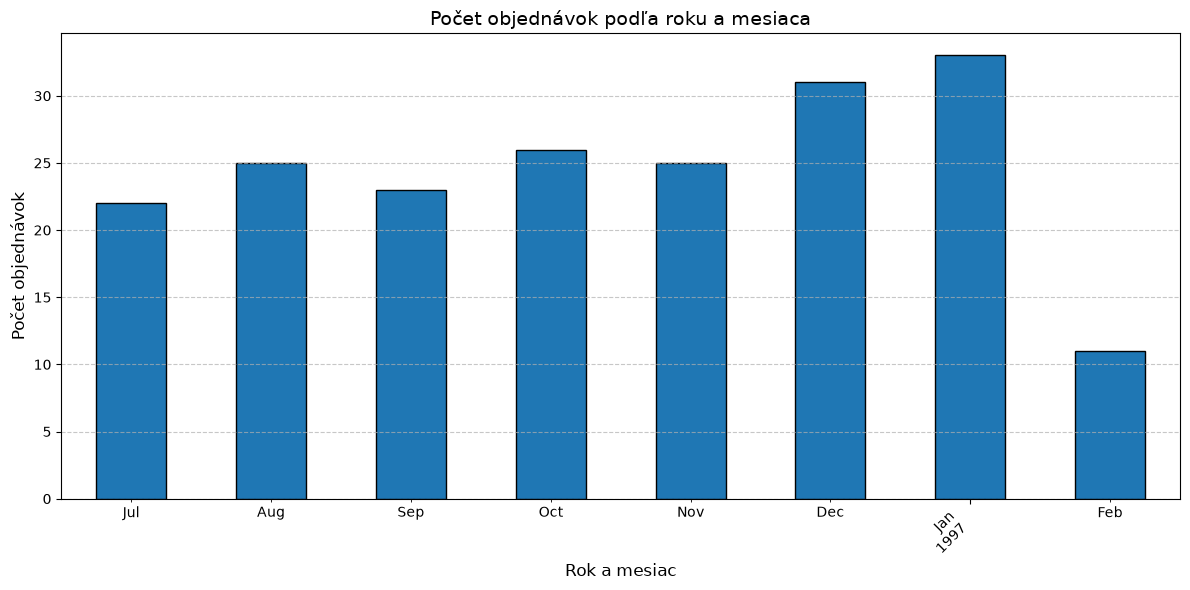

,orderid,customerid,employeeid,orderdate,shipperid
0,10248,90,5,1996-07-04,3
1,10249,81,6,1996-07-05,1
2,10250,34,4,1996-07-08,2
3,10251,84,3,1996-07-08,1
4,10252,76,4,1996-07-09,2


In [37]:
# Vaše riešenie
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
CSV_PATH = Path(r"D:\Downloads\orderss.csv")
orders = pd.read_csv(CSV_PATH, sep=",",parse_dates=["orderdate"])
min_date = orders["orderdate"].min()
max_date = orders["orderdate"].max()
monthly_orders = orders["orderdate"].dt.to_period("M").value_counts().sort_index()

plt.figure(figsize=(12, 6))
monthly_orders.plot(kind="bar", color="tab:blue", edgecolor="black")
plt.title("Počet objednávok podľa roku a mesiaca", fontsize=14)
plt.xlabel("Rok a mesiac", fontsize=12)
plt.ylabel("Počet objednávok", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

orders.head()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 2 – Historické a novšie objednávky</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Podľa časového rozloženia zvoľte <strong>hranice 1. januára 1997</strong>. Staršie objednávky budú historický batch, objednávky od tohto dátumu využijeme na simuláciu príchodu udalostí.</p>
<ul style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.7; margin-top: 6px; padding-left: 24px;"><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">historical_orders</code> budú objednávky pred hranicou,</li><li style="margin-bottom: 5px;"><code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">new_orders</code> naopak objednávky od hranice (vrátane),</li><li style="margin-bottom: 5px;">overte, že obe skupiny spolu obsahujú všetky objednávky.</li></ul>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong>Upozornenie: </strong> „Novšie“ objednávky sú stále <strong>historické záznamy</strong>. V nasledujúcich úlohách budeme ich príchod len simulovať.</div>

In [39]:
# Vaše riešenie
CUTOFF = pd.Timestamp("1997-01-01")

historical_orders = orders[
    orders["orderdate"] < CUTOFF
].copy()

new_orders = orders[
    orders["orderdate"] >= CUTOFF
].copy()

print("Historical batch:", len(historical_orders))
print("New events:", len(new_orders))

Historical batch: 152
New events: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 3 – Raw ingestion do PostgreSQL</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte databázu <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">Northwind</code>, tabuľku <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> s primárnym kľúčom <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code> a nahrajte všetky záznamy z CSV. Predpokladáme, že PostgreSQL a balíky už fungujú inštaláciu ani test verzie preto nemusíte riešiť.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Pomôcka:</strong> najskôr sa pripojte do databázy <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">postgres</code>, vytvorte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders_practice</code> s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">AUTOCOMMIT</code>, potom zmeňte pripojenie. Na opakovateľný import použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">DROP TABLE IF EXISTS</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">to_sql(..., if_exists="append", index=False)</code>.</div>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #f59e0b; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">⚠️ <strong> Upozornenie:</strong> Pri opakovanom spustení sa obsah tabuľky <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orders</code> vymaže a znovu nahrá. Nepoužívajte názov databázy, ktorá už obsahuje vaše vlastné dáta.</div>

In [41]:

print("Databáza Northwind je pripravená.")

# najskôr odstránime starú verziu tabuľky, aby sa cvičenie dalo spustiť opakovane
# najskôr odstránime starú verziu tabuľky, aby sa cvičenie dalo spustiť opakovane
with engine.begin() as conn:
    conn.execute(text("DROP TABLE IF EXISTS orders"))

    # vytvoríme zdrojovú tabuľku (zariadili sme správne zarovnanie)
    conn.execute(text("""
        CREATE TABLE orders (
        orderid INT PRIMARY KEY,
        customerid INT,
        employeeid INT,
        orderdate TIMESTAMP,
        shipperid INT
        )
    """))

# viac ako milión riadkov zapíšeme po väčších blokoch
orders.to_sql(
    "orders",
    engine,
    if_exists="append",
    index=False,
    chunksize=10000
)

print("Tabuľka orders bola načítaná.")


Databáza Northwind je pripravená.
Tabuľka orders bola načítaná.


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 4 – Batch processing</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Z historických objednávok vypočítajte <strong>počet objednávok</strong>, <strong>počet zákazníkov</strong> a <strong>percento objednávok s <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">shipperid = 3</code></strong>. Výsledok získame jednorazovo za celú historickú skupinu.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Percento vypočítate ako <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(počet objednávok dopravcu 3 / počet všetkých objednávok) * 100</code>. Výraz <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(df["shipperid"] == 3).sum()</code> spočíta vyhovujúce riadky.</div>

In [43]:
# Počet objednávok
n_orders = len(historical_orders)

# Počet unikátnych zákazníkov (používame názov stĺpca podľa vašej tabuľky, napr. customerid)
n_customers = historical_orders["customerid"].nunique()

# Percento objednávok s shipperid = 3
pct_shipper3 = (historical_orders["shipperid"] == 3).mean() * 100

print(f"Objednávok: {n_orders}")
print(f"Zákazníkov: {n_customers}")
print(f"Dopravca 3 (%): {pct_shipper3:.2f}")

Objednávok: 152
Zákazníkov: 66
Dopravca 3 (%): 38.16


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 5 – Spoločná vzorka pre tri prístupy</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na porovnanie musí každý prístup dostať <strong>rovnaké objednávky v rovnakom poradí</strong>. Z PostgreSQL vyberte novšie objednávky a zoraďte ich podľa <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderdate</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">orderid</code>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">text()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">engine.connect()</code> a pomenované parametre SQL <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:cutoff</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">:limit</code>. V tomto datasete je po hranici 44 objednávok, preto postačuje <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">SAMPLE_SIZE = 44</code>.</div>

In [44]:
# Vaše riešenie
from sqlalchemy import text

SAMPLE_SIZE = 44
CUTOFF = "1997-01-01"

query = text("""
    SELECT orderid, customerid, employeeid, orderdate, shipperid
    FROM orders
    WHERE orderdate >= :cutoff
    ORDER BY orderdate, orderid
    LIMIT :limit
""")

with engine.connect() as conn:
    new_orders_db = pd.read_sql(
        query, 
        conn, 
        params={"cutoff": CUTOFF, "limit": SAMPLE_SIZE},
        parse_dates=["orderdate"]
    )

print("Objednávok v simulácii:", len(new_orders_db))

Objednávok v simulácii: 44


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 6 – Simulácia micro-batchingu a streamingu</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Historické objednávky budeme prehrávať postupne. <strong>Streaming</strong> aktualizuje podiel dopravcu 3 po každej objednávke, <strong>micro-batch</strong> po uzavretí krátkeho časového okna. Batch poskytne výsledok až po príchode celej vzorky.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Pre tento malý dataset nastavíme <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">EVENT_DELAY_SEC = 0.04</code> (40 ms medzi objednávkami) a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">MICRO_WINDOW_SEC = 0.30</code> (približne 300 ms na dávku). Skutočné časy závisia od výkonu počítača.</div>

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok A – Nastavenia a priebežný stav</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Pripravte časové parametre, počítadlá a zoznamy na zaznamenávanie priebežných výsledkov. Pri micro-batchingu potrebujeme navyše premenné pre neuzavretú dávku.</p>

In [45]:
# Vaše riešenie
import time

EVENT_DELAY_SEC = 0.04   # umelý odstup medzi ratingmi (sekundy)
MICRO_WINDOW_SEC = 0.30   # približná dĺžka micro-batch okna (sekundy)

<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok B – Spracovanie udalostí</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Prejdite objednávky postupne. Pri streamingu priebežne zapisujte <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">(čas, počet, percento)</code>. Pri micro-batchingu spracujte nazbierané objednávky až po uplynutí okna.</p>

In [47]:
import time

# 1. Inicializácia premenných
stream_count, stream_sum = 0, 0.0
stream_updates = []

micro_count, micro_sum = 0, 0.0
micro_pending_count, micro_pending_sum = 0, 0.0
micro_updates = []

start_time = time.perf_counter()
last_flush = start_time

# 2. Spracovanie udalostí v cykle
for idx, row in new_orders_db.iterrows():
    # STREAMING: okamžité spracovanie
    stream_count += 1
    if row["shipperid"] == 3:
        stream_sum += 1.0
    
    elapsed = time.perf_counter() - start_time
    stream_pct = (stream_sum / stream_count) * 100 if stream_count > 0 else 0
    stream_updates.append((elapsed, stream_count, stream_pct))
    
    # Umelý odstup medzi udalosťami
    time.sleep(EVENT_DELAY_SEC)
    
    # MICRO-BATCH: pripočítanie do dočasného zásobníku
    micro_pending_count += 1
    if row["shipperid"] == 3:
        micro_pending_sum += 1.0
        
    current_time = time.perf_counter()
    
    # Ak ubehol čas micro-batch okna, "vyplavíme" dávku
    if (current_time - last_flush) >= MICRO_WINDOW_SEC:
        micro_count += micro_pending_count
        micro_sum += micro_pending_sum
        
        elapsed_mb = current_time - start_time
        micro_pct = (micro_sum / micro_count) * 100 if micro_count > 0 else 0
        micro_updates.append((elapsed_mb, micro_count, micro_pct))
        
        # Reset dočasných počítadiel pre ďalšie okno
        micro_pending_count = 0
        micro_pending_sum = 0.0
        last_flush = current_time

print("Spracovanie streamu a micro-batchov úspešne dokončené.")

Spracovanie streamu a micro-batchov úspešne dokončené.


<h3 style="margin: 20px 0 10px; font-size: 17px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827;">Krok C – Posledná dávka a batch</h3>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Nezabudnite spracovať poslednú nedokončenú micro-batch dávku. Nakoniec vypočítajte jednorazový batch výsledok pre tú istú vzorku a overte rovnosť výsledných percent.</p>

In [48]:
# Vaše riešenie
# 1. Spracovanie zvyšku v micro-batch (ak niečo zostalo v zásobníku)
if micro_pending_count > 0:
    micro_count += micro_pending_count
    micro_sum += micro_pending_sum
    
    elapsed_mb = time.perf_counter() - start_time
    micro_pct = (micro_sum / micro_count) * 100 if micro_count > 0 else 0
    micro_updates.append((elapsed_mb, micro_count, micro_pct))

# 2. Výpočet pre jednorazový batch na tej istej vzorke (new_orders_db)
batch_total = len(new_orders_db)
batch_shipper3_pct = (new_orders_db["shipperid"] == 3).mean() * 100

print(f"Počet objednávok: {batch_total}")
print(f"Batch (%): {batch_shipper3_pct:.2f}")
print(f"Micro-batch (%): {(micro_sum / micro_count * 100):.2f}" if micro_count > 0 else "Micro-batch (%): 0")
print(f"Streaming (%): {stream_pct:.2f}")

Počet objednávok: 44
Batch (%): 22.73
Micro-batch (%): 22.73
Streaming (%): 22.73


<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 7 – Grafy priebežných výsledkov</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Vytvorte <strong>tri samostatné grafy</strong> pod sebou. V prvom zobrazte jednorazový batch bod, v druhom schodovitý priebeh micro-batchingu a v treťom streamingovú krivku. Použite spoločné osi, aby boli percentá porovnateľné.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong>Poznámka:</strong> Použite <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plt.subplots(3, 1, sharex=True, sharey=True)</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">scatter()</code>, <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">step(where="post")</code> a <code style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">plot()</code>.</div>

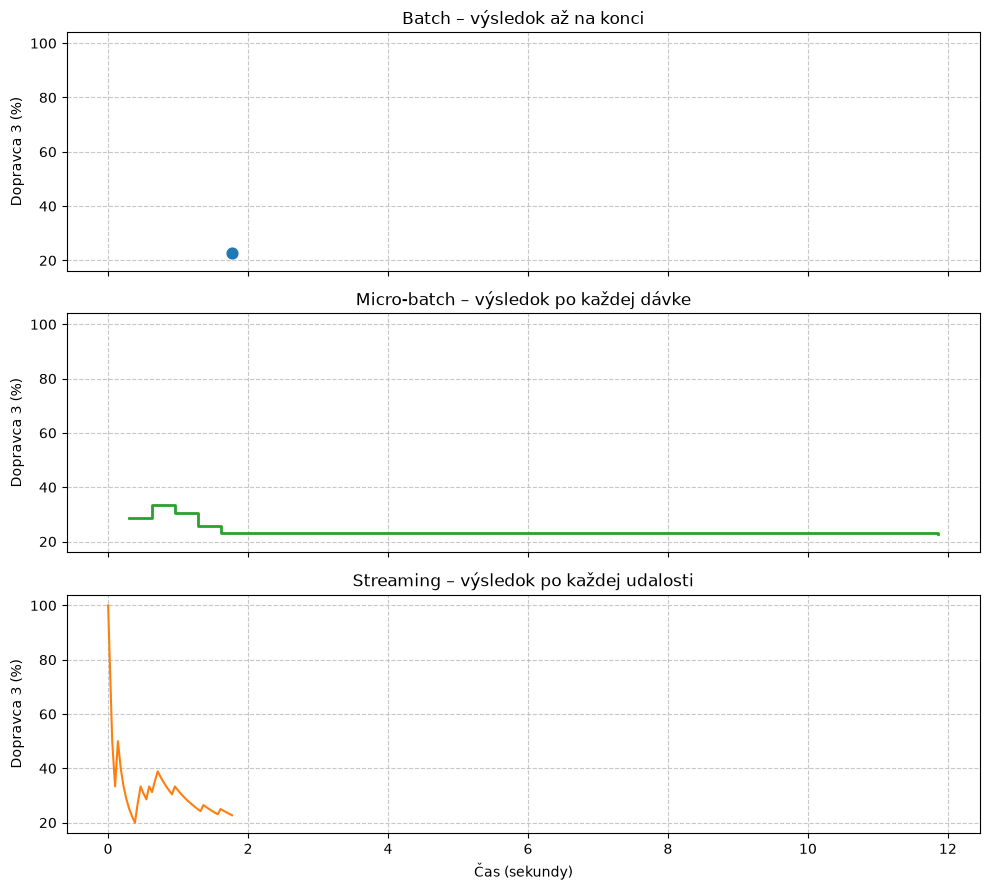

In [49]:
# Vaše riešenie
import matplotlib.pyplot as plt

# Príprava dát zo zoznamov updates
micro_times = [u[0] for u in micro_updates]
micro_pcts = [u[2] for u in micro_updates]

stream_times = [u[0] for u in stream_updates]
stream_pcts = [u[2] for u in stream_updates]

# Celkový čas simulácie pre umiestnenie jednorazového batch bodu
total_time = stream_times[-1] if stream_times else 0

# Vytvorenie 3 podgrafov so zdieľanými osami (sharex=True, sharey=True)
fig, axes = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(10, 9))

# 1. Graf: Jednorazový Batch (bod na konci)
axes[0].scatter([total_time], [batch_shipper3_pct], color="tab:blue", s=60, zorder=3)
axes[0].set_title("Batch – výsledok až na konci")
axes[0].set_ylabel("Dopravca 3 (%)")
axes[0].grid(True, linestyle="--", alpha=0.7)

# 2. Graf: Micro-batch (schodovitý priebeh pomocou step s where="post")
axes[1].step(micro_times, micro_pcts, where="post", color="tab:green", linewidth=2)
axes[1].set_title("Micro-batch – výsledok po každej dávke")
axes[1].set_ylabel("Dopravca 3 (%)")
axes[1].grid(True, linestyle="--", alpha=0.7)

# 3. Graf: Streaming (krivka pomocou plot)
axes[2].plot(stream_times, stream_pcts, color="tab:orange", linewidth=1.5)
axes[2].set_title("Streaming – výsledok po každej udalosti")
axes[2].set_xlabel("Čas (sekundy)")
axes[2].set_ylabel("Dopravca 3 (%)")
axes[2].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">💻 Úloha 8 – Frekvencia aktualizácií a prvý výsledok</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">Na troch grafoch znázornite, koľkokrát sa priebežný výsledok aktualizoval. Potom vytvorte jednoduchú tabuľku, ktorá porovná <strong>čas prvého výsledku</strong>.</p>
<div style="margin-top: 12px; background-color: #f9fafb; border-left: 4px solid #60a5fa; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">💡 <strong> Poznámka:</strong> Pri počte aktualizácií nie je vhodné zdieľať os Y: batch má jeden výsledok, streaming jeden po každej udalosti. Os X zdieľajte.</div>

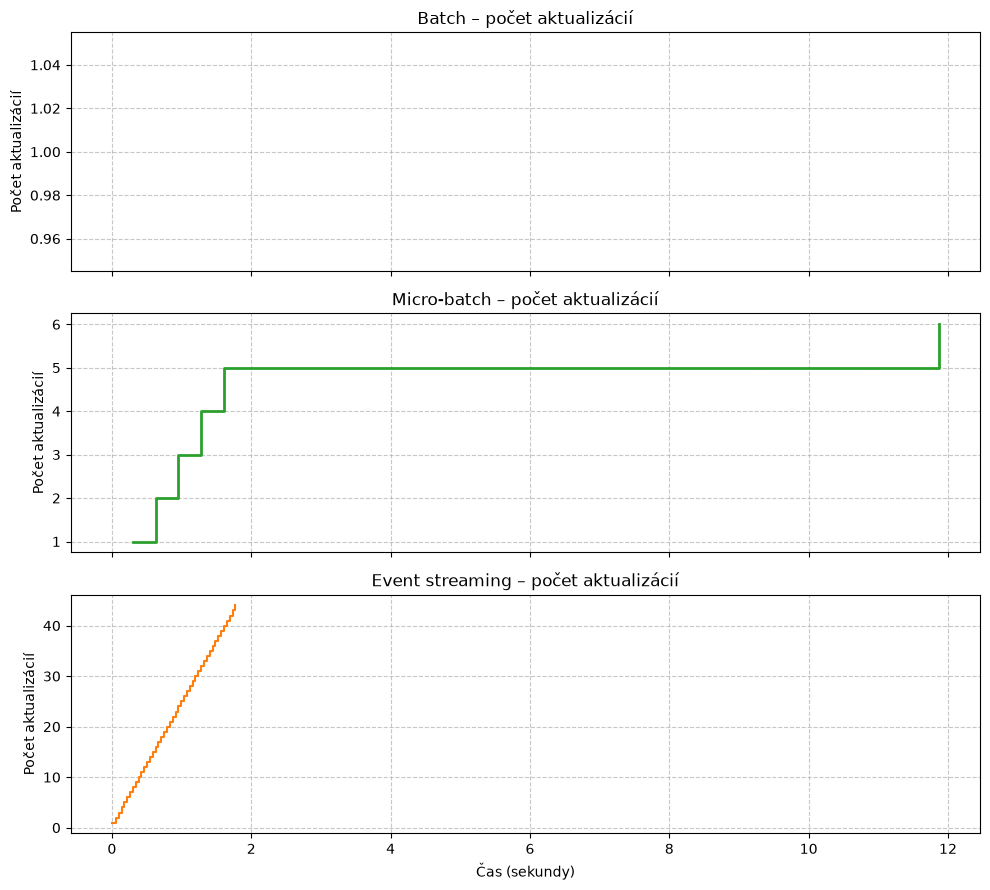


Porovnanie prístupov:


,Prístup,Čas prvého výsledku (s),Celkový počet aktualizácií
0,Batch,1.771522,1
1,Micro-batch,0.302590,6
2,Streaming,0.000691,44


In [50]:
# Vaše riešenie
import matplotlib.pyplot as plt
import pandas as pd

# 1. Príprava kumulatívnych počtov aktualizácií pre jednotlivé prístupy
# Batch: iba 1 aktualizácia na konci
batch_updates_count = [1] if len(new_orders_db) > 0 else [0]
batch_times = [total_time]

# Micro-batch: kumulatívny počet aktualizácií (1, 2, 3...)
micro_update_counts = list(range(1, len(micro_updates) + 1))
micro_times = [u[0] for u in micro_updates]

# Streaming: kumulatívny počet aktualizácií (1, 2, 3...)
stream_update_counts = list(range(1, len(stream_updates) + 1))
stream_times = [u[0] for u in stream_updates]

# 2. Vytvorenie grafov (zdieľaná os X, nezdieľaná os Y)
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(10, 9))

# Batch graf
axes[0].step(batch_times, batch_updates_count, where="post", color="tab:blue", linewidth=2)
axes[0].set_title("Batch – počet aktualizácií")
axes[0].set_ylabel("Počet aktualizácií")
axes[0].grid(True, linestyle="--", alpha=0.7)

# Micro-batch graf
axes[1].step(micro_times, micro_update_counts, where="post", color="tab:green", linewidth=2)
axes[1].set_title("Micro-batch – počet aktualizácií")
axes[1].set_ylabel("Počet aktualizácií")
axes[1].grid(True, linestyle="--", alpha=0.7)

# Streaming graf
axes[2].step(stream_times, stream_update_counts, where="post", color="tab:orange", linewidth=1.5)
axes[2].set_title("Event streaming – počet aktualizácií")
axes[2].set_xlabel("Čas (sekundy)")
axes[2].set_ylabel("Počet aktualizácií")
axes[2].grid(True, linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# 3. Vytvorenie tabuľky porovnávajúcej čas prvého výsledku
first_batch_time = total_time if batch_times else None
first_micro_time = micro_times[0] if micro_times else None
first_stream_time = stream_times[0] if stream_times else None

comparison_df = pd.DataFrame({
    "Prístup": ["Batch", "Micro-batch", "Streaming"],
    "Čas prvého výsledku (s)": [first_batch_time, first_micro_time, first_stream_time],
    "Celkový počet aktualizácií": [len(batch_times), len(micro_updates), len(stream_updates)]
})

print("\nPorovnanie prístupov:")
display(comparison_df)

<h2 style="margin: 24px 0 16px; font-size: 20px; font-weight: 600; font-family: 'Segoe UI', Roboto, sans-serif; color: #111827; border-bottom: 2px solid #e5e7eb; padding-bottom: 6px;">
  📘 Kontrola Git repozitára po 8. týždni
</h2>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Po dokončení všetkých úloh z 8. týždňa skontrolujte, či máte vo svojom Git
  repozitári vytvorenú samostatnú vetvu
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  a či sa v nej nachádza vypracovaný notebook vytvorený počas cvičenia.
</p>
<p style="font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.65; margin: 8px 0 12px;">
  Obsah vetvy
  <span style="background-color: #e5e7eb; color: #111827; font-family: monospace; padding: 2px 5px; border-radius: 4px;">week-08</span>
  by mal mať približne nasledujúcu štruktúru:
</p>
<pre style="background: #f9fafb; color: #111827; padding: 14px; border-radius: 7px; overflow: auto; font-size: 13px; line-height: 1.7; font-family: ui-monospace, SFMono-Regular, Menlo, monospace;">week-08
│
├── ratings.csv
├── orders.csv
│
├── batch_streaming.ipynb
└── batch_streaming_orders.ipynb
</pre>
<div style="margin-top: 12px; background-color: #fefce8; border-left: 4px solid #eab308; padding: 12px; border-radius: 4px; font-family: 'Segoe UI', Roboto, sans-serif; color: #1f2937; line-height: 1.6;">
  ⚠️ <strong>Kontrola GitHubu:</strong> Skontrolujte, či sa všetky uvedené súbory
  nachádzajú aj vo vzdialenom repozitári na GitHube. Ak ich vidíte iba lokálne
  vo VS Code, zmeny ešte neboli úspešne odoslané pomocou
  <strong>commit</strong> a <strong>push</strong>.
</div>